In [0]:

prefixos_alvo = ("bronze_", "silver_", "gold_")

tabelas_df = spark.sql("SHOW TABLES")

lista_tabelas = [row.tableName for row in tabelas_df.collect()]

print("Iniciando a varredura e remoção de tabelas...")

for tabela in lista_tabelas:
    # Verifica se a tabela começa com algum dos prefixos indesejados
    if tabela.startswith(prefixos_alvo):
        try:
            spark.sql(f"DROP TABLE IF EXISTS {tabela}")
            print(f"[SUCESSO] Tabela dropada: {tabela}")
        except Exception as e:
            print(f"[AVISO] Erro ao dropar a tabela '{tabela}': {str(e)}")

print("\nLimpeza concluída")

Iniciando a varredura e remoção de tabelas...
[SUCESSO] Tabela dropada: bronze_ab_test
[SUCESSO] Tabela dropada: bronze_consumers
[SUCESSO] Tabela dropada: bronze_dq_ingestion_observability
[SUCESSO] Tabela dropada: bronze_orders
[SUCESSO] Tabela dropada: bronze_restaurants
[SUCESSO] Tabela dropada: gold_dim_consumers
[SUCESSO] Tabela dropada: gold_dim_restaurants
[SUCESSO] Tabela dropada: gold_dm_ab_test_retention
[SUCESSO] Tabela dropada: gold_dm_ab_test_rfv_metrics
[SUCESSO] Tabela dropada: gold_dm_ab_test_summary
[SUCESSO] Tabela dropada: gold_dm_customer_rfv_segments
[SUCESSO] Tabela dropada: gold_dm_financial_cpo_projection
[SUCESSO] Tabela dropada: gold_fct_experiments
[SUCESSO] Tabela dropada: gold_fct_orders
[SUCESSO] Tabela dropada: silver_ab_test
[SUCESSO] Tabela dropada: silver_consumers
[SUCESSO] Tabela dropada: silver_orders
[SUCESSO] Tabela dropada: silver_restaurants

Limpeza concluída


## Tratamento e ETL

In [0]:
import os
import time
import uuid
import urllib.request
import tarfile
import logging
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd

import pyspark.sql.functions as F
import pyspark.sql.types as T
from pyspark.sql.window import Window

start_time_notebook = time.time()

In [0]:
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger("iFood_ETL")

CATALOG_NAME = "main"
SCHEMA_NAME = "default"
VOLUME_NAME = "ifood_raw_data"
BASE_WORK_DIR = f"/Volumes/{CATALOG_NAME}/{SCHEMA_NAME}/{VOLUME_NAME}"

try:
    spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG_NAME}.{SCHEMA_NAME}.{VOLUME_NAME}")
except Exception:
    BASE_WORK_DIR = "/tmp/ifood_raw_data"
    os.makedirs(BASE_WORK_DIR, exist_ok=True)

DATASETS_CONFIG = {
    "orders": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/order.json.gz",
    "consumers": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/consumer.csv.gz",
    "restaurants": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/restaurant.csv.gz",
    "ab_test": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/ab_test_ref.tar.gz"
}

def download_with_retry(url: str, target_path: str, max_retries: int = 3, delay: int = 2):
    for attempt in range(1, max_retries + 1):
        try:
            urllib.request.urlretrieve(url, target_path)
            return
        except Exception as e:
            if attempt == max_retries:
                raise e
            time.sleep(delay * attempt)

for name, url in DATASETS_CONFIG.items():
    file_name = url.split("/")[-1]
    local_path = os.path.join(BASE_WORK_DIR, file_name)
    
    file_exists = False
    try:
        if 'dbutils' in globals():
            dbutils.fs.ls(f"dbfs:{local_path}")
            file_exists = True
        else:
            file_exists = os.path.exists(local_path)
    except Exception:
        file_exists = False

    if not file_exists:
        download_with_retry(url, local_path)
        
    if file_name.endswith(".tar.gz"):
        try:
            with tarfile.open(local_path, "r:gz") as tar:
                tar.extractall(path=BASE_WORK_DIR)
        except Exception as e:
            logger.error(f"Erro ao extrair {name}: {str(e)}")
            raise e

In [0]:
run_id = str(uuid.uuid4())
batch_start = F.current_timestamp()

# 1. Leitura dos ficheiros brutos a partir do volume
df_raw_consumers = spark.read.option("header", "true").csv(os.path.join(BASE_WORK_DIR, 'consumer.csv.gz'))
df_raw_restaurants = spark.read.option("header", "true").csv(os.path.join(BASE_WORK_DIR, 'restaurant.csv.gz'))
df_raw_orders = spark.read.json(os.path.join(BASE_WORK_DIR, 'order.json.gz'))
df_raw_ab = spark.read.option("header", "true").csv(os.path.join(BASE_WORK_DIR, 'ab_test_ref.csv'))

# 2. Função de ingestão para a camada Bronze com metadados
def append_to_bronze(df, table_name: str, source_file: str):
    (
        df
        .withColumn("_batch_id", F.lit(run_id))
        .withColumn("_ingested_at", batch_start)
        .withColumn("_source_file", F.lit(source_file))
        .write
        .format("delta")
        .mode("append")
        .saveAsTable(f"bronze_{table_name}")
    )

append_to_bronze(df_raw_consumers, "consumers", "consumer.csv.gz")
append_to_bronze(df_raw_restaurants, "restaurants", "restaurant.csv.gz")
append_to_bronze(df_raw_orders, "orders", "order.json.gz")
append_to_bronze(df_raw_ab, "ab_test", "ab_test_ref.csv")

# 3. Validação consolidada de qualidade dos dados (Data Quality)
dq_orders = df_raw_orders.select(
    F.count(F.lit(1)).alias("orders_total"),
    F.countDistinct("order_id").alias("orders_distinct"),
    F.sum(F.when(F.col("order_id").isNull(), 1).otherwise(0)).alias("orders_missing_id"),
    F.sum(F.when(F.col("customer_id").isNull(), 1).otherwise(0)).alias("orders_missing_customer"),
    F.sum(F.when(F.col("merchant_id").isNull(), 1).otherwise(0)).alias("orders_missing_merchant"),
    F.sum(F.when(F.col("order_total_amount").cast("double") < 0, 1).otherwise(0)).alias("orders_negative_amount")
).first()

dq_consumers = df_raw_consumers.select(
    F.count(F.lit(1)).alias("consumers_total"),
    F.countDistinct("customer_id").alias("consumers_distinct"),
    F.sum(F.when(F.col("customer_id").isNull(), 1).otherwise(0)).alias("consumers_missing_id")
).first()

dq_restaurants = df_raw_restaurants.select(
    F.count(F.lit(1)).alias("restaurants_total"),
    F.countDistinct("id").alias("restaurants_distinct"),
    F.sum(F.when(F.col("id").isNull(), 1).otherwise(0)).alias("restaurants_missing_id")
).first()

obs_data = [(
    run_id,
    dq_orders["orders_total"],
    dq_orders["orders_total"] - dq_orders["orders_distinct"],
    dq_orders["orders_missing_id"],
    dq_orders["orders_missing_customer"],
    dq_orders["orders_missing_merchant"],
    dq_orders["orders_negative_amount"],
    dq_consumers["consumers_total"],
    dq_consumers["consumers_total"] - dq_consumers["consumers_distinct"],
    dq_consumers["consumers_missing_id"],
    dq_restaurants["restaurants_total"],
    dq_restaurants["restaurants_total"] - dq_restaurants["restaurants_distinct"],
    dq_restaurants["restaurants_missing_id"]
)]

obs_cols = [
    "run_id", "pedidos_totais", "pedidos_duplicados", "pedidos_sem_order_id",
    "pedidos_sem_customer_id", "pedidos_sem_merchant_id", "pedidos_valor_negativo",
    "clientes_totais", "clientes_duplicados", "clientes_sem_customer_id",
    "restaurantes_totais", "restaurantes_duplicados", "restaurantes_sem_merchant_id"
]

# 4. Gravação da tabela de observabilidade padronizada na camada Bronze
df_obs = (
    spark.createDataFrame(obs_data, obs_cols)
    .withColumn("created_at", F.current_timestamp())
)

df_obs.write.format("delta").mode("append").saveAsTable("bronze_dq_ingestion_observability")

# 5. Exibição imediata das métricas de qualidade do lote processado
df_obs.display()

run_id,pedidos_totais,pedidos_duplicados,pedidos_sem_order_id,pedidos_sem_customer_id,pedidos_sem_merchant_id,pedidos_valor_negativo,clientes_totais,clientes_duplicados,clientes_sem_customer_id,restaurantes_totais,restaurantes_duplicados,restaurantes_sem_merchant_id,created_at
e9d59998-8b64-4944-a21f-7dc53da1e395,3670826,1237852,0,8505,0,0,806156,0,0,7292,0,0,2026-10-20T00:58:27.822Z


In [0]:
def save_to_silver(df, table_name: str) -> None:
    df.write.format("delta").mode("overwrite").saveAsTable(f"silver_{table_name}")

df_silver_consumers = (
    spark.read.table("bronze_consumers")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("customer_id").isNotNull())
    .withColumn("customer_id", F.trim(F.col("customer_id")))
    .withColumn("language", F.lower(F.trim(F.col("language"))))
    .withColumn("active", F.coalesce(F.col("active").cast("boolean"), F.lit(True)))
    .withColumn("created_at", F.expr("try_to_timestamp(created_at)"))
    .dropDuplicates(["customer_id"])
    .select("customer_id", "customer_name", "language", "created_at", "active", "customer_phone_area", "customer_phone_number")
)
save_to_silver(df_silver_consumers, "consumers")

df_silver_restaurants = (
    spark.read.table("bronze_restaurants")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("id").isNotNull())
    .withColumn("restaurant_id", F.trim(F.col("id")))
    .withColumn("merchant_city", F.trim(F.col("merchant_city")))
    .withColumn("merchant_state", F.upper(F.trim(F.col("merchant_state"))))
    .withColumn("enabled", F.coalesce(F.col("enabled").cast("boolean"), F.lit(True)))
    .dropDuplicates(["restaurant_id"])
    .select("restaurant_id", "merchant_city", "merchant_state", "enabled")
)
save_to_silver(df_silver_restaurants, "restaurants")

df_silver_ab_test = (
    spark.read.table("bronze_ab_test")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("customer_id").isNotNull())
    .withColumn("customer_id", F.trim(F.col("customer_id")))
    .withColumn("is_target", F.lower(F.trim(F.col("is_target"))))
    .dropDuplicates(["customer_id"])
    .select("customer_id", "is_target")
)
save_to_silver(df_silver_ab_test, "ab_test")

window_dup = Window.partitionBy("order_id")
window_time_desc = Window.partitionBy("order_id").orderBy(F.col("order_created_at").desc())

df_silver_orders = (
    spark.read.table("bronze_orders")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("order_id").isNotNull())
    .withColumn("order_id", F.trim(F.col("order_id")))
    .withColumn("customer_id", F.trim(F.col("customer_id")))
    .withColumn("merchant_id", F.trim(F.col("merchant_id")))
    .withColumn("order_created_at", F.expr("try_to_timestamp(order_created_at)"))
    .withColumn("order_total_amount", F.col("order_total_amount").cast("double"))
    .filter(F.col("order_total_amount") >= 0)
    .withColumn("total_ocorrencias", F.count("order_id").over(window_dup))
    .withColumn("rn_desc", F.row_number().over(window_time_desc))
    .filter((F.col("total_ocorrencias") == 1) | ((F.col("total_ocorrencias") > 1) & (F.col("rn_desc") > 1)))
    .drop("total_ocorrencias", "rn_desc")
    .select(
        "order_id", "customer_id", "merchant_id", "order_created_at",
        "order_total_amount", "delivery_address_city", "origin_platform", "order_scheduled", "items"
    )
)
save_to_silver(df_silver_orders, "orders")

In [0]:
def save_to_gold(df, table_name: str) -> None:
    df.write.format("delta").mode("overwrite").saveAsTable(f"gold_{table_name}")

df_silver_consumers = spark.read.table("silver_consumers")
df_silver_restaurants = spark.read.table("silver_restaurants")
df_silver_orders = spark.read.table("silver_orders")
df_silver_ab_test = spark.read.table("silver_ab_test")

# Tabela de Experimentos
df_fct_experiments = (
    df_silver_ab_test
    .withColumn("experiment_id", F.lit("retencao_dez18"))
    .withColumnRenamed("is_target", "variant_name")
    .select("customer_id", "experiment_id", "variant_name")
)
save_to_gold(df_fct_experiments, "fct_experiments")

# B) Dimensão Clientes com Métricas LTV
df_consumer_metrics = (
    df_silver_orders
    .groupBy("customer_id")
    .agg(
        F.count("order_id").alias("lifetime_orders"),
        F.round(F.sum("order_total_amount"), 2).alias("lifetime_gmv"),
        F.round(F.avg("order_total_amount"), 2).alias("avg_ticket_size")
    )
)

df_gold_consumers = (
    df_silver_consumers.alias("c")
    .join(df_consumer_metrics.alias("m"), F.col("c.customer_id") == F.col("m.customer_id"), "left")
    .select(
        F.col("c.customer_id"),
        F.col("c.customer_name"),
        F.col("c.language"),
        F.col("c.created_at").alias("customer_since"),
        F.col("c.active"),
        F.col("c.customer_phone_area"),
        F.col("c.customer_phone_number"),
        F.coalesce(F.col("m.lifetime_orders"), F.lit(0)).alias("lifetime_orders"),
        F.coalesce(F.col("m.lifetime_gmv"), F.lit(0.0)).alias("lifetime_gmv"),
        F.coalesce(F.col("m.avg_ticket_size"), F.lit(0.0)).alias("avg_ticket_size")
    )
)
save_to_gold(df_gold_consumers, "dim_consumers")

# C) Dimensão Restaurantes
df_merchant_metrics = (
    df_silver_orders
    .groupBy("merchant_id")
    .agg(
        F.count("order_id").alias("total_orders_fulfilled"),
        F.round(F.sum("order_total_amount"), 2).alias("total_revenue"),
        F.round(F.avg("order_total_amount"), 2).alias("average_order_value")
    )
)

df_gold_restaurants = (
    df_silver_restaurants.alias("r")
    .join(df_merchant_metrics.alias("m"), F.col("r.restaurant_id") == F.col("m.merchant_id"), "left")
    .select(
        F.col("r.restaurant_id"),
        F.col("r.merchant_city"),
        F.col("r.merchant_state"),
        F.col("r.enabled"),
        F.coalesce(F.col("m.total_orders_fulfilled"), F.lit(0)).alias("total_orders_fulfilled"),
        F.coalesce(F.col("m.total_revenue"), F.lit(0.0)).alias("total_revenue"),
        F.coalesce(F.col("m.average_order_value"), F.lit(0.0)).alias("average_order_value")
    )
)
save_to_gold(df_gold_restaurants, "dim_restaurants")

# D) Fato Pedidos
df_gold_orders = (
    df_silver_orders
    .select(
        "order_id", "customer_id", "merchant_id", "order_created_at",
        "order_total_amount", "delivery_address_city", "origin_platform", "order_scheduled"
    )
)
save_to_gold(df_gold_orders, "fct_orders")

end_time_etl = time.time()
etl_duration_seconds = end_time_etl - start_time_notebook
etl_duration_minutes = etl_duration_seconds / 60

print(f"✅ Pipeline ETL Concluído (Bronze -> Silver -> Gold)!")
print(f"⏱️ Tempo de processamento do ETL: {etl_duration_seconds:.2f} segundos ({etl_duration_minutes:.2f} minutos).")
print(f"Iniciando análises e processamento estatístico...")

✅ Pipeline ETL Concluído (Bronze -> Silver -> Gold)!
⏱️ Tempo de processamento do ETL: 271.79 segundos (4.53 minutos).
Iniciando análises e processamento estatístico...


## Análise

In [0]:
orders = (
    spark.table('gold_fct_orders')
    .withColumn('reference_date', F.date_format(F.col("order_created_at"), "yyyy-MM-dd"))
    .withColumn('reference_month', F.date_format(F.date_trunc("month", F.col("order_created_at")), "yyyy-MM-dd"))
)

restaurants = spark.table('gold_dim_restaurants')

# 1. Mapeamento de usuários: quem não é 'target' vira 'control'
users = (
    spark.table('gold_dim_consumers')
    .join(
        spark.table('gold_fct_experiments').filter(F.col('experiment_id') == 'retencao_dez18'),
        on='customer_id',
        how='left'
    )
    .withColumn(
        'ab_test_group',
        F.when(F.col('variant_name') == 'target', 'target').otherwise('control')
    )
    .drop('experiment_id', 'variant_name')
)

# 2. LEFT JOIN a partir de orders garantindo que 100% dos pedidos sejam mantidos
base = (
    orders
    .join(users.select("customer_id", "ab_test_group"), on="customer_id", how="left")
    .withColumn(
        "ab_test_group",
        F.coalesce(F.col("ab_test_group"), F.lit("control"))
    )
)

In [0]:
df_retencao = (
    base
    .groupBy("customer_id", "ab_test_group")
    .agg(
        F.max(F.when(F.col("reference_month") == "2018-12-01", 1).otherwise(0)).alias("comprou_m0"),
        F.max(F.when(F.col("reference_month") == "2019-01-01", 1).otherwise(0)).alias("comprou_m1")
    )
    .filter(F.col("comprou_m0") == 1)
    .groupBy("ab_test_group")
    .agg(
        F.count("customer_id").alias("base_users_m0"),
        F.sum("comprou_m1").alias("retained_users_m1")
    )
    .withColumn("reference_month", F.lit("2018-12-01"))
    .withColumn("retention_m1_percentage", F.round((F.col("retained_users_m1") * 100.0) / F.col("base_users_m0"), 2))
)

df_resumo_mensal = (
    base
    .groupBy("reference_month", "ab_test_group")
    .agg(
        F.countDistinct("customer_id").alias("active_users"),
        F.count("order_id").alias("total_orders"),
        F.countDistinct("merchant_id").alias("unique_merchants"),
        F.round(F.sum("order_total_amount"), 2).alias("monthly_gmv")
    )
    .withColumn("frequency", F.round(F.col("total_orders") / F.col("active_users"), 2))
    .withColumn("aov", F.round(F.col("monthly_gmv") / F.col("total_orders"), 2))
    .withColumn("gmv_per_user", F.round(F.col("monthly_gmv") / F.col("active_users"), 2))
)

resumo_mensal = (
    df_resumo_mensal
    .join(
        df_retencao.select("reference_month", "ab_test_group", "base_users_m0", "retained_users_m1", "retention_m1_percentage"),
        on=["reference_month", "ab_test_group"],
        how="left"
    )
    .orderBy(F.col("reference_month").asc(), F.col("ab_test_group").desc())
)

resumo_total = (
    base
    .groupBy("ab_test_group")
    .agg(
        F.countDistinct("customer_id").alias("total_users"),
        F.count("order_id").alias("total_orders"),
        F.countDistinct("merchant_id").alias("unique_merchants"),
        F.round(F.sum("order_total_amount"), 2).alias("total_gmv")
    )
    .withColumn("frequency", F.round(F.col("total_orders") / F.col("total_users"), 2))
    .withColumn("aov", F.round(F.col("total_gmv") / F.col("total_orders"), 2))
    .withColumn("gmv_per_user", F.round(F.col("total_gmv") / F.col("total_users"), 2))
    .join(
        df_retencao.select("ab_test_group", "base_users_m0", "retained_users_m1", "retention_m1_percentage"),
        on="ab_test_group",
        how="left"
    )
    .orderBy(F.col("ab_test_group").desc())
)

resumo_mensal.display()
resumo_total.display()

reference_month,ab_test_group,active_users,total_orders,unique_merchants,monthly_gmv,frequency,aov,gmv_per_user,base_users_m0,retained_users_m1,retention_m1_percentage
2018-12-01,target,312919,719794,6853,3.426529299E7,2.3,47.6,109.5,312919,165878,53.01
2018-12-01,control,241676,518058,6826,2.491503824E7,2.14,48.09,103.09,241676,110889,45.88
2019-01-01,target,298702,696404,6581,3.344264188E7,2.33,48.02,111.96,null,null,null
2019-01-01,control,229935,498718,6543,2.402946351E7,2.17,48.18,104.51,null,null,null


ab_test_group,total_users,total_orders,unique_merchants,total_gmv,frequency,aov,gmv_per_user,base_users_m0,retained_users_m1,retention_m1_percentage
target,445743,1416198,7227,6.770793487E7,3.18,47.81,151.9,312919,165878,53.01
control,360723,1016776,7198,4.894450175E7,2.82,48.14,135.68,241676,110889,45.88


In [0]:
stats_freq = (
    base.groupBy("customer_id", "ab_test_group")
    .agg(F.count("order_id").alias("user_orders"))
    .groupBy("ab_test_group")
    .agg(F.count("user_orders").alias("n"), F.avg("user_orders").alias("mean"), F.var_samp("user_orders").alias("var"))
    .toPandas().set_index("ab_test_group")
)

stats_aov = (
    base.groupBy("ab_test_group")
    .agg(F.count("order_total_amount").alias("n"), F.avg("order_total_amount").alias("mean"), F.var_samp("order_total_amount").alias("var"))
    .toPandas().set_index("ab_test_group")
)

# Novo: Estatísticas de GMV por Usuário (base para validação do GMV Total)
stats_gmv = (
    base.groupBy("customer_id", "ab_test_group")
    .agg(F.sum("order_total_amount").alias("user_gmv"))
    .groupBy("ab_test_group")
    .agg(F.count("user_gmv").alias("n"), F.avg("user_gmv").alias("mean"), F.var_samp("user_gmv").alias("var"))
    .toPandas().set_index("ab_test_group")
)

ret = (
    resumo_total
    .select("ab_test_group", "base_users_m0", "retained_users_m1")
    .toPandas().set_index("ab_test_group")
)

# Teste Z Proporção (Retenção M+1)
xt, nt = ret.loc["target", "retained_users_m1"], ret.loc["target", "base_users_m0"]
xc, nc = ret.loc["control", "retained_users_m1"], ret.loc["control", "base_users_m0"]
pt, pc = xt / nt, xc / nc
p_pool = (xt + xc) / (nt + nc)
se_ret = (p_pool * (1 - p_pool) * (1 / nt + 1 / nc)) ** 0.5
z_ret = (pt - pc) / se_ret
p_ret = 1 - norm.cdf(z_ret)

# Teste Z Média (Frequência)
se_freq = ((stats_freq.loc["target", "var"] / stats_freq.loc["target", "n"]) + 
           (stats_freq.loc["control", "var"] / stats_freq.loc["control", "n"])) ** 0.5
z_freq = (stats_freq.loc["target", "mean"] - stats_freq.loc["control", "mean"]) / se_freq
p_freq = 1 - norm.cdf(z_freq)

# Teste Z Média Bilateral (AOV)
se_aov = ((stats_aov.loc["target", "var"] / stats_aov.loc["target", "n"]) + 
          (stats_aov.loc["control", "var"] / stats_aov.loc["control", "n"])) ** 0.5
z_aov = (stats_aov.loc["target", "mean"] - stats_aov.loc["control", "mean"]) / se_aov
p_aov = 2 * (1 - norm.cdf(abs(z_aov)))

# Novo: Teste Z Média Bilateral (GMV por Usuário / GMV Total)
se_gmv = ((stats_gmv.loc["target", "var"] / stats_gmv.loc["target", "n"]) + 
          (stats_gmv.loc["control", "var"] / stats_gmv.loc["control", "n"])) ** 0.5
z_gmv = (stats_gmv.loc["target", "mean"] - stats_gmv.loc["control", "mean"]) / se_gmv
p_gmv = 2 * (1 - norm.cdf(abs(z_gmv)))

dados_testes = [
    ("Retenção", "Z-prop unilateral", float(pc), float(pt), float(p_ret), bool(p_ret < 0.05)),
    ("Frequência", "Z-mean unilateral", float(stats_freq.loc["control", "mean"]), float(stats_freq.loc["target", "mean"]), float(p_freq), bool(p_freq < 0.05)),
    ("AOV", "Z-mean bilateral", float(stats_aov.loc["control", "mean"]), float(stats_aov.loc["target", "mean"]), float(p_aov), bool(p_aov < 0.05)),
    ("GMV por Usuário", "Z-mean bilateral", float(stats_gmv.loc["control", "mean"]), float(stats_gmv.loc["target", "mean"]), float(p_gmv), bool(p_gmv < 0.05))
]

schema_testes = T.StructType([
    T.StructField("metrica", T.StringType(), True),
    T.StructField("teste", T.StringType(), True),
    T.StructField("ctrl", T.DoubleType(), True),
    T.StructField("tgt", T.DoubleType(), True),
    T.StructField("p_valor", T.DoubleType(), True),
    T.StructField("significativo", T.BooleanType(), True)
])

df_resultados = (
    spark.createDataFrame(dados_testes, schema_testes)
    .withColumn("ctrl", F.when(F.col("metrica") == "Retenção", F.round(F.col("ctrl"), 4)).otherwise(F.round(F.col("ctrl"), 2)))
    .withColumn("tgt", F.when(F.col("metrica") == "Retenção", F.round(F.col("tgt"), 4)).otherwise(F.round(F.col("tgt"), 2)))
    .withColumn("p_valor", F.round(F.col("p_valor"), 5))
)

df_resultados.display()

metrica,teste,ctrl,tgt,p_valor,significativo
Retenção,Z-prop unilateral,0.4588,0.5301,0.0,true
Frequência,Z-mean unilateral,2.82,3.18,0.0,true
AOV,Z-mean bilateral,48.14,47.81,0.04183,true
GMV por Usuário,Z-mean bilateral,135.68,151.9,0.0,true


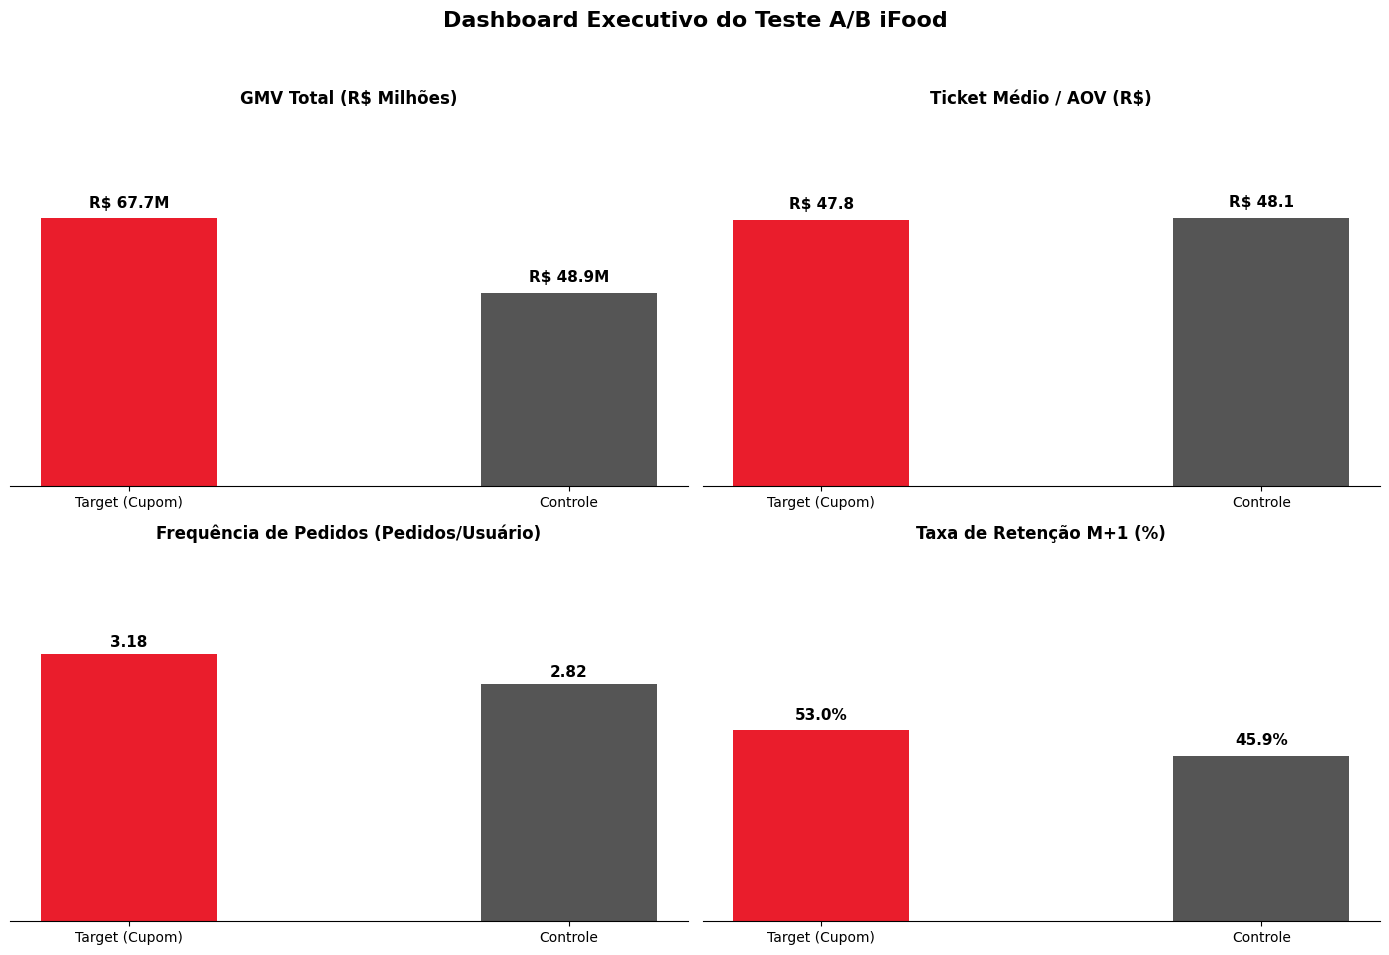

In [0]:
plt.close('all')

df_resumo_pd = resumo_total.toPandas().set_index("ab_test_group")

gmv_target = float(df_resumo_pd.loc['target', 'total_gmv']) / 1e6
gmv_control = float(df_resumo_pd.loc['control', 'total_gmv']) / 1e6
aov_target = float(df_resumo_pd.loc['target', 'aov'])
aov_control = float(df_resumo_pd.loc['control', 'aov'])
freq_target = float(df_resumo_pd.loc['target', 'frequency'])
freq_control = float(df_resumo_pd.loc['control', 'frequency'])
ret_target = float(df_resumo_pd.loc['target', 'retention_m1_percentage'])
ret_control = float(df_resumo_pd.loc['control', 'retention_m1_percentage'])

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
colors = ['#ea1d2c', '#555555']
groups = ['Target (Cupom)', 'Controle']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

def clean_axis(ax, title):
    ax.set_title(title, fontsize=12, fontweight='bold', pad=15)
    ax.grid(False)
    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)
    ax.spines['bottom'].set_visible(True)
    ax.set_yticks([])

# GMV
ax1 = axes[0, 0]
gmv_vals = [gmv_target, gmv_control]
bars1 = ax1.bar(groups, gmv_vals, color=colors, width=0.4)
clean_axis(ax1, 'GMV Total (R$ Milhões)')
ax1.set_ylim(0, max(gmv_vals) * 1.35)
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 2, f'R$ {y:.1f}M', ha='center', va='bottom', fontweight='bold', fontsize=11)

# AOV
ax2 = axes[0, 1]
aov_vals = [aov_target, aov_control]
bars2 = ax2.bar(groups, aov_vals, color=colors, width=0.4)
clean_axis(ax2, 'Ticket Médio / AOV (R$)')
ax2.set_ylim(0, max(aov_vals) * 1.35)
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 1.5, f'R$ {y:.1f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Frequência
ax3 = axes[1, 0]
freq_vals = [freq_target, freq_control]
bars3 = ax3.bar(groups, freq_vals, color=colors, width=0.4)
clean_axis(ax3, 'Frequência de Pedidos (Pedidos/Usuário)')
ax3.set_ylim(0, max(freq_vals) * 1.35)
for bar in bars3:
    y = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2.0, y + 0.05, f'{y:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# Retenção
ax4 = axes[1, 1]
ret_vals = [ret_target, ret_control]
bars4 = ax4.bar(groups, ret_vals, color=colors, width=0.4)
clean_axis(ax4, 'Taxa de Retenção M+1 (%)')
ax4.set_ylim(0, 100)
for bar in bars4:
    y = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2.0, y + 2, f'{y:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.suptitle('Dashboard Executivo do Teste A/B iFood', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

display(fig)
plt.close(fig)

📊 INDICADORES EXECUTIVOS DE VIABILIDADE DO TESTE A/B


Indicador,Valor
Lift de Retenção,7.1
Usuários Ativos (Dez/18),312919.0
Retidos Incrementais/Mês,22300.3
GMV/Usuário (Jan/19),112.17
Receita Incremental/Mês,375202
Custo iFood (Déficit Líquido),4266475.0
Tempo de Payback,11.4


mes_timeline,gmv_incremental_mes,receita_ifood_incremental_mes,custo_total_cupons_mes,resultado_ifood_mes,resultado_ifood_acumulado,roi_ifood_acumulado
Mês 0 (Campanha),1.876343312E7,2814514.97,7080990.0,-4266475.03,-4266475.03,0.397
M+1,2501344.2,375201.63,51959.79,323241.84,-3943233.19,0.447
M+2,2501344.2,375201.63,25979.89,349221.74,-3594011.46,0.498
M+3,2501344.2,375201.63,12989.95,362211.68,-3231799.77,0.549
M+4,2501344.2,375201.63,0.0,375201.63,-2856598.14,0.602
M+5,2501344.2,375201.63,0.0,375201.63,-2481396.51,0.654
M+6,2501344.2,375201.63,0.0,375201.63,-2106194.88,0.706
M+7,2501344.2,375201.63,0.0,375201.63,-1730993.26,0.759
M+8,2501344.2,375201.63,0.0,375201.63,-1355791.63,0.811
M+9,2501344.2,375201.63,0.0,375201.63,-980590.0,0.863


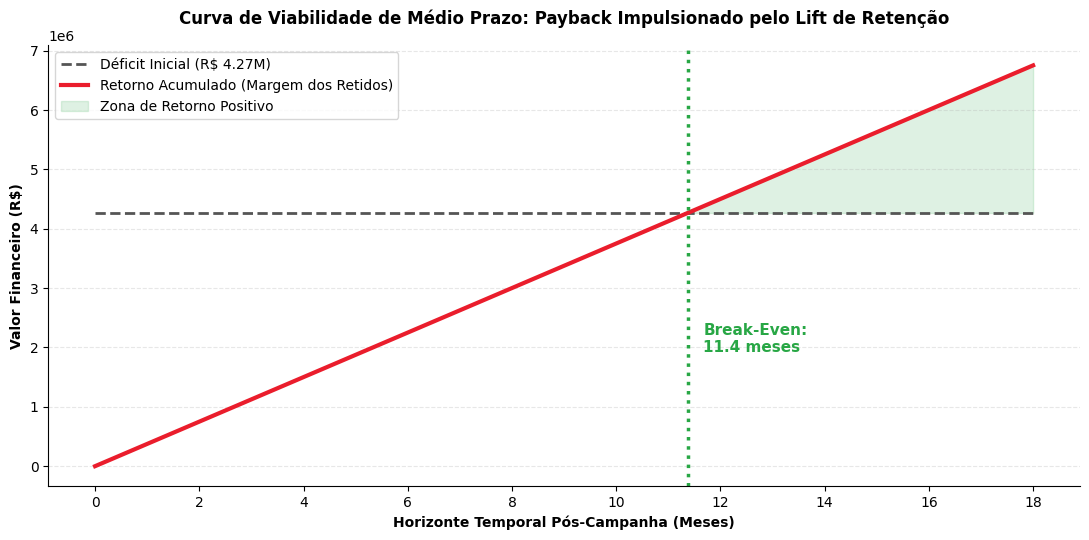

In [0]:
plt.close('all')

df_v = resumo_total.toPandas().set_index("ab_test_group")

# Big Numbers (resultados teste A/B)
gmv_target = float(df_v.loc["target", "total_gmv"])
gmv_control = float(df_v.loc["control", "total_gmv"])
pedidos_target = float(df_v.loc["target", "total_orders"])
base_coorte_m0 = float(df_v.loc["target", "base_users_m0"])
ret_target = float(df_v.loc["target", "retained_users_m1"] / base_coorte_m0)
ret_control = float(df_v.loc["control", "retained_users_m1"] / float(df_v.loc["control", "base_users_m0"]))

# Métricas de ticket médio e frequência
aov_control = float(df_v.loc["control", "aov"])
freq_recorrente_jan = float(
    resumo_mensal
    .filter((F.col("reference_month") == "2019-01-01") & (F.col("ab_test_group") == "target"))
    .select("frequency")
    .first()[0]
)

take_rate = 0.15
CUSTO_UNITARIO_CUPOM = 5.00
PCT_PEDIDOS_COM_CUPOM = 1.00

# Indicadores Chave
lift_retencao_pp = (ret_target - ret_control) * 100.0
usuarios_ativos_dez = base_coorte_m0
retidos_incrementais_mes = base_coorte_m0 * (ret_target - ret_control)
gmv_usuario_jan = freq_recorrente_jan * aov_control
receita_incremental_mes = retidos_incrementais_mes * (gmv_usuario_jan * take_rate)

receita_imediata_teste = (gmv_target - gmv_control) * take_rate
custo_total_cupons_teste = pedidos_target * PCT_PEDIDOS_COM_CUPOM * CUSTO_UNITARIO_CUPOM
deficit_campanha = custo_total_cupons_teste - receita_imediata_teste

payback_meses = deficit_campanha / receita_incremental_mes


indicadores_resumo = [
    ("Lift de Retenção", f"{lift_retencao_pp:.1f}"),
    ("Usuários Ativos (Dez/18)", f"{usuarios_ativos_dez:.1f}"),
    ("Retidos Incrementais/Mês", f"{retidos_incrementais_mes:.1f}"),
    ("GMV/Usuário (Jan/19)", f"{gmv_usuario_jan:.2f}"),
    ("Receita Incremental/Mês", f"{receita_incremental_mes:.0f}"),
    ("Custo iFood (Déficit Líquido)", f"{deficit_campanha:.1f}"),
    ("Tempo de Payback", f"{payback_meses:.1f}")
]

schema_resumo = T.StructType([
    T.StructField("Indicador", T.StringType(), True),
    T.StructField("Valor", T.StringType(), True)
])

print("=" * 60)
print("📊 INDICADORES EXECUTIVOS DE VIABILIDADE DO TESTE A/B")
print("=" * 60)
spark.createDataFrame(indicadores_resumo, schema_resumo).display()

# desmame pós-campanha para retidos (subsídio caindo gradualmente) - M0 = 100%, M1 = 20%, M2 = 10%, M3 = 5%, M4+ = 0% 
decay_cupom_pct = {
    0: 1.00,
    1: 0.20,
    2: 0.10,
    3: 0.05
}

dados_projecao = []
rec_acumulada = 0.0
custo_acumulado = 0.0

for m in range(19):
    rotulo_mes = "Mês 0 (Campanha)" if m == 0 else f"M+{m}"
    
    if m == 0:
        gmv_mes = gmv_target - gmv_control
        rec_mes = gmv_mes * take_rate
        custo_mes = custo_total_cupons_teste
    else:
        # Volume dos clientes retidos
        gmv_mes = retidos_incrementais_mes * gmv_usuario_jan
        rec_mes = gmv_mes * take_rate
        # Subsídio residual de transição (desmame realista pós-campanha)
        pct_cupom_mes = decay_cupom_pct.get(m, 0.00)
        pedidos_mes_retidos = retidos_incrementais_mes * freq_recorrente_jan
        custo_mes = pedidos_mes_retidos * pct_cupom_mes * CUSTO_UNITARIO_CUPOM
    
    res_mes = rec_mes - custo_mes
    rec_acumulada += rec_mes
    custo_acumulado += custo_mes
    res_acumulado = rec_acumulada - custo_acumulado
    roi_acumulado = rec_acumulada / custo_acumulado if custo_acumulado > 0 else 0.0
    
    dados_projecao.append({
        "mes_timeline": rotulo_mes,
        "gmv_incremental_mes": round(gmv_mes, 2),
        "receita_ifood_incremental_mes": round(rec_mes, 2),
        "custo_total_cupons_mes": round(custo_mes, 2),
        "resultado_ifood_mes": round(res_mes, 2),
        "resultado_ifood_acumulado": round(res_acumulado, 2),
        "roi_ifood_acumulado": round(roi_acumulado, 3)
    })

schema_projecao = T.StructType([
    T.StructField("mes_timeline", T.StringType(), True),
    T.StructField("gmv_incremental_mes", T.DoubleType(), True),
    T.StructField("receita_ifood_incremental_mes", T.DoubleType(), True),
    T.StructField("custo_total_cupons_mes", T.DoubleType(), True),
    T.StructField("resultado_ifood_mes", T.DoubleType(), True),
    T.StructField("resultado_ifood_acumulado", T.DoubleType(), True),
    T.StructField("roi_ifood_acumulado", T.DoubleType(), True)
])

df_projecao_financeira = spark.createDataFrame(dados_projecao, schema_projecao)
df_projecao_financeira.display()


df_proj_pd = df_projecao_financeira.toPandas()
meses_idx = np.arange(len(df_proj_pd))

fig, ax = plt.subplots(figsize=(11, 5.5))
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

deficit_linha = [deficit_campanha] * len(meses_idx)
retorno_linha = [m * receita_incremental_mes for m in meses_idx]

ax.plot(meses_idx, deficit_linha, color='#555555', linestyle='--', linewidth=2, label=f'Déficit Inicial (R$ {deficit_campanha/1e6:.2f}M)')
ax.plot(meses_idx, retorno_linha, color='#ea1d2c', linewidth=3, label='Retorno Acumulado (Margem dos Retidos)')

ax.fill_between(
    meses_idx, retorno_linha, deficit_linha,
    where=(np.array(retorno_linha) >= np.array(deficit_linha)),
    color='#28a745', alpha=0.15, interpolate=True, label='Zona de Retorno Positivo'
)

if 0 < payback_meses <= 18:
    ax.axvline(x=payback_meses, color='#28a745', linestyle=':', linewidth=2.5)
    ax.text(
        payback_meses + 0.3, float(deficit_campanha) * 0.45,
        f'Break-Even:\n{payback_meses:.1f} meses',
        color='#28a745', fontweight='bold', fontsize=11
    )

ax.set_title('Curva de Viabilidade de Médio Prazo: Payback Impulsionado pelo Lift de Retenção', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Horizonte Temporal Pós-Campanha (Meses)', fontsize=10, fontweight='bold')
ax.set_ylabel('Valor Financeiro (R$)', fontsize=10, fontweight='bold')
ax.set_xticks(range(0, 19, 2))
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(frameon=True, facecolor='white', loc='upper left')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
display(fig)    
plt.close(fig)

ordem,faixa_pedidos,total_usuarios,usuarios_retidos,taxa_retencao_%,lift_mais_um_pedido_pp
1,1 pedido,300530,105285,35.03,null
2,2 pedidos,111625,61386,54.99,19.96
3,3 pedidos,55200,37534,68.0,13.009999999999998
4,4+ pedidos,87240,72562,83.18,15.180000000000007


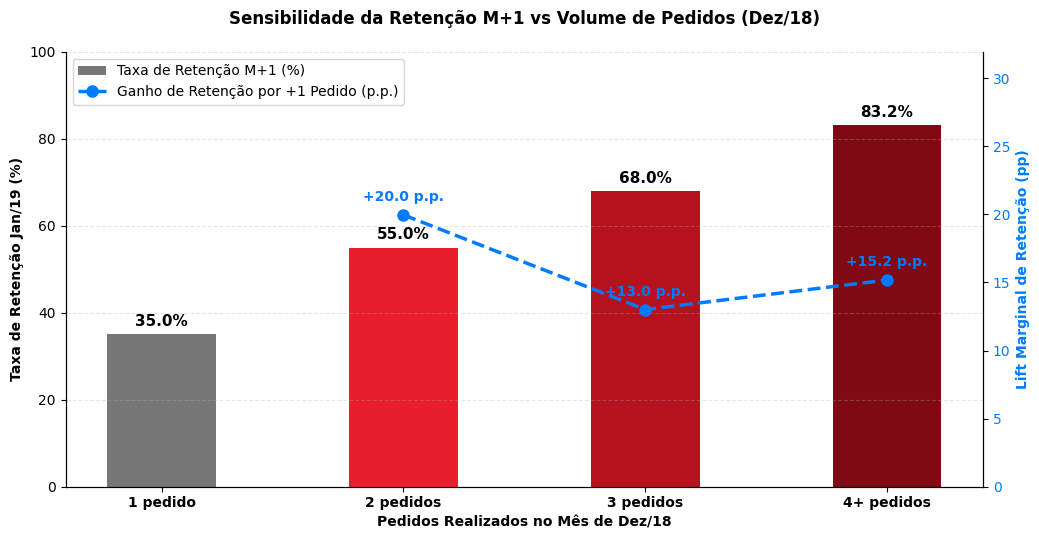

In [0]:
plt.close('all')

df_faixas_pedidos = (
    base
    .groupBy("customer_id")
    .agg(
        F.countDistinct(F.when(F.col("reference_month") == "2018-12-01", F.col("order_id"))).alias("pedidos_dez"),
        F.max(F.when(F.col("reference_month") == "2019-01-01", 1).otherwise(0)).alias("recomprou_jan")
    )
    .filter(F.col("pedidos_dez") >= 1)
    .withColumn("ordem",
        F.when(F.col("pedidos_dez") == 1, 1)
        .when(F.col("pedidos_dez") == 2, 2)
        .when(F.col("pedidos_dez") == 3, 3)
        .otherwise(4)
    )
    .withColumn("faixa_pedidos",
        F.when(F.col("ordem") == 1, "1 pedido")
        .when(F.col("ordem") == 2, "2 pedidos")
        .when(F.col("ordem") == 3, "3 pedidos")
        .otherwise("4+ pedidos")
    )
    .groupBy("ordem", "faixa_pedidos")
    .agg(
        F.count("customer_id").alias("total_usuarios"),
        F.sum("recomprou_jan").alias("usuarios_retidos")
    )
    .withColumn("taxa_retencao_%", F.round((F.col("usuarios_retidos") / F.col("total_usuarios")) * 100, 2))
    .orderBy("ordem")
)

pdf_curva = df_faixas_pedidos.toPandas()
pdf_curva['lift_mais_um_pedido_pp'] = pdf_curva['taxa_retencao_%'].diff()

spark.createDataFrame(pdf_curva).display()

fig, ax1 = plt.subplots(figsize=(10.5, 5.5))
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

x = np.arange(len(pdf_curva['faixa_pedidos']))
bars = ax1.bar(
    x, pdf_curva['taxa_retencao_%'], 
    color=['#777777', '#ea1d2c', '#b5121e', '#800a13'], 
    width=0.45, 
    label='Taxa de Retenção M+1 (%)'
)

for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2.0, y + 1.2, f'{y:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax2 = ax1.twinx()
ax2.plot(
    x[1:], pdf_curva['lift_mais_um_pedido_pp'][1:], 
    color='#007bff', marker='o', markersize=8, linewidth=2.5, 
    linestyle='--', label='Ganho de Retenção por +1 Pedido (p.p.)'
)

for i in range(1, len(pdf_curva)):
    val = pdf_curva['lift_mais_um_pedido_pp'].iloc[i]
    ax2.annotate(f'+{val:.1f} p.p.', (x[i], val), textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold', color='#007bff', fontsize=10)

ax1.set_title('Sensibilidade da Retenção M+1 vs Volume de Pedidos (Dez/18)', fontsize=12, fontweight='bold', pad=20)
ax1.set_xlabel('Pedidos Realizados no Mês de Dez/18', fontsize=10, fontweight='bold')
ax1.set_ylabel('Taxa de Retenção Jan/19 (%)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Lift Marginal de Retenção (pp)', color='#007bff', fontsize=10, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#007bff')

ax1.set_xticks(x)
ax1.set_xticklabels(pdf_curva['faixa_pedidos'], fontsize=10, fontweight='bold')
ax1.set_ylim(0, 100)
ax2.set_ylim(0, max(pdf_curva['lift_mais_um_pedido_pp'].dropna()) * 1.6)

ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, facecolor='white')

plt.tight_layout()
display(fig)
plt.close(fig)

🎯 NOVO TESTE: MONOCOMPRADORES COM TETO DE 1 CUPOM E LIFT DE 10 PP


Métrica / Premissa,Valor Projetado
Monocompradores Elegíveis (Jan/19),285.5k usuários
Grupo Target (90%),256.9k usuários
Grupo Controle (10%),28.5k usuários
AOV Orgânico (Controle),R$ 48.47
AOV Target Estimado,R$ 48.14
Frequência Mensal Observada,1.00 pedido
Frequência M+1 Calculada,1.135 pedidos
Teto de Cupons por Usuário,1 cupom
Total de Cupons Utilizados,256.9k cupons
Custo Total dos Cupons (M0),R$ 1.28M


mes_timeline,gmv_incremental_mes,receita_ifood_mes,custo_cupons_mes,cpo_ifood_mes,receita_ifood_por_pedido,resultado_liquido_mes,receita_acumulada,resultado_acumulado,roi_ifood_mes,roi_acumulado
Mês 0 (Campanha),1584232.04,237634.81,1284545.0,4.41,7.22,-1046910.19,237634.81,-1046910.19,0.185,0.185
M+1,1413385.85,212007.88,0.0,0.0,7.27,212007.88,449642.68,-834902.32,0.0,0.35
M+2,1413385.85,212007.88,0.0,0.0,7.27,212007.88,661650.56,-622894.44,0.0,0.515
M+3,1413385.85,212007.88,0.0,0.0,7.27,212007.88,873658.44,-410886.56,0.0,0.68
M+4,1413385.85,212007.88,0.0,0.0,7.27,212007.88,1085666.31,-198878.69,0.0,0.845
M+5,1413385.85,212007.88,0.0,0.0,7.27,212007.88,1297674.19,13129.19,0.0,1.01
M+6,1413385.85,212007.88,0.0,0.0,7.27,212007.88,1509682.07,225137.07,0.0,1.175
M+7,1413385.85,212007.88,0.0,0.0,7.27,212007.88,1721689.94,437144.94,0.0,1.34
M+8,1413385.85,212007.88,0.0,0.0,7.27,212007.88,1933697.82,649152.82,0.0,1.505
M+9,1413385.85,212007.88,0.0,0.0,7.27,212007.88,2145705.7,861160.7,0.0,1.67


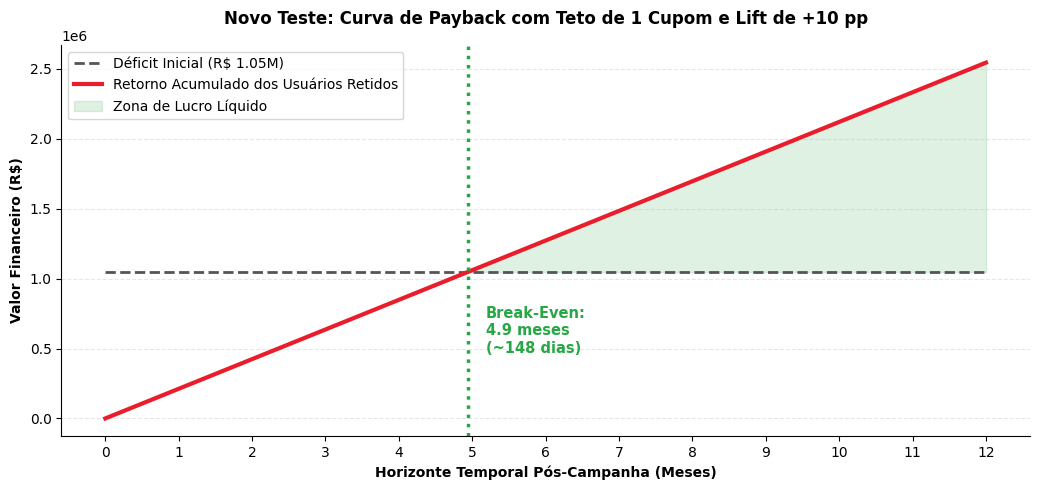

In [0]:
pct_target = 0.90
take_rate = 0.15
novo_cpo = 5.00
max_cupons_por_usuario = 1
conversao_cupom = 1
lift_frequencia_estimado = 0.135
lift_retencao_estimado = 0.10

pdf_jan = (
    base
    .filter(F.col("reference_month") == "2019-01-01")
    .groupBy("customer_id")
    .agg(
        F.count("order_id").alias("pedidos_jan"),
        F.sum("order_total_amount").alias("gmv_jan")
    )
    .filter(F.col("pedidos_jan") == 1)
    .agg(
        F.count("customer_id").alias("total_monocompradores_jan"),
        F.sum("pedidos_jan").alias("total_pedidos_jan"),
        F.sum("gmv_jan").alias("total_gmv_jan")
    )
    .toPandas()
)

total_monocompradores_jan = float(pdf_jan["total_monocompradores_jan"].values[0])
total_pedidos_jan = float(pdf_jan["total_pedidos_jan"].values[0])
total_gmv_jan = float(pdf_jan["total_gmv_jan"].values[0])

freq_ctrl = total_pedidos_jan / total_monocompradores_jan 
aov_ctrl = total_gmv_jan / total_pedidos_jan
gmv_medio_user_ctrl = freq_ctrl * aov_ctrl

freq_m1 = freq_ctrl * (1.0 + lift_frequencia_estimado)

AUDIENCIA_TARGET = float(np.round(total_monocompradores_jan * pct_target))
audiencia_control = float(np.round(total_monocompradores_jan * (1.0 - pct_target)))

aov_ctrl_teste = float(df_v.loc["control", "aov"])
aov_tgt_teste = float(df_v.loc["target", "aov"])
delta_aov_empirico_pct = (aov_tgt_teste - aov_ctrl_teste) / aov_ctrl_teste

aov_target_ponderado = aov_ctrl * (1.0 + (delta_aov_empirico_pct * conversao_cupom))
pedidos_target = AUDIENCIA_TARGET * freq_m1

cupons_utilizados_target = float(min(pedidos_target * conversao_cupom, AUDIENCIA_TARGET * max_cupons_por_usuario))
gmv_target = pedidos_target * aov_target_ponderado
receita_incremental_m0 = (gmv_target - (AUDIENCIA_TARGET * gmv_medio_user_ctrl)) * take_rate
custo_total_subsidy_m0 = cupons_utilizados_target * novo_cpo
deficit_liquido_campanha = custo_total_subsidy_m0 - receita_incremental_m0

usuarios_salvos_churn = AUDIENCIA_TARGET * lift_retencao_estimado
margem_recorrente_mensal = usuarios_salvos_churn * ((freq_m1 * aov_ctrl) * take_rate)
payback_deficit_liquido = deficit_liquido_campanha / margem_recorrente_mensal if (deficit_liquido_campanha > 0 and margem_recorrente_mensal > 0) else 0.0

indicadores_novo_teste = [
    ("Monocompradores Elegíveis (Jan/19)", f"{total_monocompradores_jan/1e3:.1f}k usuários"),
    ("Grupo Target (90%)", f"{AUDIENCIA_TARGET/1e3:.1f}k usuários"),
    ("Grupo Controle (10%)", f"{audiencia_control/1e3:.1f}k usuários"),
    ("AOV Orgânico (Controle)", f"R$ {aov_ctrl:.2f}"),
    ("AOV Target Estimado", f"R$ {aov_target_ponderado:.2f}"),
    ("Frequência Mensal Observada", f"{freq_ctrl:.2f} pedido"),
    ("Frequência M+1 Calculada", f"{freq_m1:.3f} pedidos"),
    ("Teto de Cupons por Usuário", f"{max_cupons_por_usuario} cupom"),
    ("Total de Cupons Utilizados", f"{cupons_utilizados_target/1e3:.1f}k cupons"),
    ("Custo Total dos Cupons (M0)", f"R$ {custo_total_subsidy_m0/1e6:.2f}M"),
    ("Receita Incremental Imediata (M0)", f"R$ {receita_incremental_m0/1e3:.1f}k"),
    ("Déficit Inicial da Ação", f"-R$ {deficit_liquido_campanha/1e6:.2f}M"),
    ("Lift de Retenção Estimado", f"+{lift_retencao_estimado*100:.1f} pp"),
    ("Usuários Salvos do Churn / Mês", f"{usuarios_salvos_churn/1e3:.1f}k usuários"),
    ("Margem Orgânica Recorrente / Mês", f"R$ {margem_recorrente_mensal/1e3:.1f}k"),
    ("Tempo de Payback Estimado", f"{payback_deficit_liquido:.1f} meses")
]

schema_resumo_teste = T.StructType([
    T.StructField("Métrica / Premissa", T.StringType(), True),
    T.StructField("Valor Projetado", T.StringType(), True)
])

print("=" * 65)
print("🎯 NOVO TESTE: MONOCOMPRADORES COM TETO DE 1 CUPOM E LIFT DE 10 PP")
print("=" * 65)
spark.createDataFrame(indicadores_novo_teste, schema_resumo_teste).display()

dados_projecao = []
for mes_idx in range(13):
    rotulo = "Mês 0 (Campanha)" if mes_idx == 0 else f"M+{mes_idx}"
    
    if mes_idx == 0:
        gmv_mes = gmv_target - (AUDIENCIA_TARGET * gmv_medio_user_ctrl)
        rec_mes = receita_incremental_m0
        custo_mes = custo_total_subsidy_m0
        cpo_mes = custo_mes / pedidos_target
        rec_por_pedido = (pedidos_target * aov_target_ponderado * take_rate) / pedidos_target
        roi_mes = rec_mes / custo_mes if custo_mes > 0 else 0.0
    else:
        pedidos_org_salvos = usuarios_salvos_churn * freq_m1
        gmv_mes = pedidos_org_salvos * aov_ctrl
        rec_mes = margem_recorrente_mensal
        custo_mes = 0.0
        cpo_mes = 0.0
        rec_por_pedido = aov_ctrl * take_rate
        roi_mes = 0.0
        
    res_mes = rec_mes - custo_mes
    rec_acum = receita_incremental_m0 + (mes_idx * margem_recorrente_mensal)
    res_acum = rec_acum - custo_total_subsidy_m0
    roi_acum = rec_acum / custo_total_subsidy_m0 if custo_total_subsidy_m0 > 0 else 0.0
    
    dados_projecao.append({
        "mes_timeline": rotulo,
        "gmv_incremental_mes": float(round(gmv_mes, 2)),
        "receita_ifood_mes": float(round(rec_mes, 2)),
        "custo_cupons_mes": float(round(custo_mes, 2)),
        "cpo_ifood_mes": float(round(cpo_mes, 2)),
        "receita_ifood_por_pedido": float(round(rec_por_pedido, 2)),
        "resultado_liquido_mes": float(round(res_mes, 2)),
        "receita_acumulada": float(round(rec_acum, 2)),
        "resultado_acumulado": float(round(res_acum, 2)),
        "roi_ifood_mes": float(round(roi_mes, 3)),
        "roi_acumulado": float(round(roi_acum, 3))
    })

schema_projecao = T.StructType([
    T.StructField("mes_timeline", T.StringType(), True),
    T.StructField("gmv_incremental_mes", T.DoubleType(), True),
    T.StructField("receita_ifood_mes", T.DoubleType(), True),
    T.StructField("custo_cupons_mes", T.DoubleType(), True),
    T.StructField("cpo_ifood_mes", T.DoubleType(), True),
    T.StructField("receita_ifood_por_pedido", T.DoubleType(), True),
    T.StructField("resultado_liquido_mes", T.DoubleType(), True),
    T.StructField("receita_acumulada", T.DoubleType(), True),
    T.StructField("resultado_acumulado", T.DoubleType(), True),
    T.StructField("roi_ifood_mes", T.DoubleType(), True),
    T.StructField("roi_acumulado", T.DoubleType(), True)
])

df_projecao_financeira = spark.createDataFrame(dados_projecao, schema_projecao)
df_projecao_financeira.display()

df_proj_pd = df_projecao_financeira.toPandas()
meses_num = np.arange(len(df_proj_pd))

plt.close('all')
fig, ax = plt.subplots(figsize=(10.5, 5))
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

ax.plot(meses_num, [deficit_liquido_campanha] * len(meses_num), color='#555555', linestyle='--', linewidth=2, label=f'Déficit Inicial (R$ {deficit_liquido_campanha/1e6:.2f}M)')
ax.plot(meses_num, [m * margem_recorrente_mensal for m in meses_num], color='#ea1d2c', linewidth=3, label='Retorno Acumulado dos Usuários Retidos')

ax.fill_between(
    meses_num, [m * margem_recorrente_mensal for m in meses_num], [deficit_liquido_campanha] * len(meses_num),
    where=(np.array([m * margem_recorrente_mensal for m in meses_num]) >= np.array([deficit_liquido_campanha] * len(meses_num))),
    color='#28a745', alpha=0.15, interpolate=True, label='Zona de Lucro Líquido'
)

if 0 < payback_deficit_liquido <= 12:
    ax.axvline(x=payback_deficit_liquido, color='#28a745', linestyle=':', linewidth=2.5)
    ax.text(
        payback_deficit_liquido + 0.25, float(deficit_liquido_campanha) * 0.45,
        f'Break-Even:\n{payback_deficit_liquido:.1f} meses\n(~{int(payback_deficit_liquido * 30)} dias)',
        color='#28a745', fontweight='bold', fontsize=10.5
    )

ax.set_title('Novo Teste: Curva de Payback com Teto de 1 Cupom e Lift de +10 pp', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Horizonte Temporal Pós-Campanha (Meses)', fontsize=10, fontweight='bold')
ax.set_ylabel('Valor Financeiro (R$)', fontsize=10, fontweight='bold')
ax.set_xticks(range(0, 13))
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(frameon=True, facecolor='white', loc='upper left')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
display(fig)
plt.close(fig)

In [0]:
max_date = orders.select(F.max("reference_date").cast("string")).first()[0]

df_rfv_base = (
    orders
    .groupBy("customer_id")
    .agg(
        F.datediff(F.lit(max_date), F.max("reference_date")).alias("recencia_dias"),
        F.countDistinct("order_id").alias("frequencia_pedidos"),
        F.sum("order_total_amount").alias("valor_monetario")
    )
)

quantiles = df_rfv_base.selectExpr(
    "percentile_approx(recencia_dias, array(0.2, 0.4, 0.6, 0.8)) as r_quant",
    "percentile_approx(frequencia_pedidos, array(0.2, 0.4, 0.6, 0.8)) as f_quant",
    "percentile_approx(valor_monetario, array(0.2, 0.4, 0.6, 0.8)) as v_quant"
).first()

r_q, f_q, v_q = quantiles["r_quant"], quantiles["f_quant"], quantiles["v_quant"]

df_rfv_scores = (
    df_rfv_base
    .withColumn("R",
        F.when(F.col("recencia_dias") <= r_q[0], 5)
        .when(F.col("recencia_dias") <= r_q[1], 4)
        .when(F.col("recencia_dias") <= r_q[2], 3)
        .when(F.col("recencia_dias") <= r_q[3], 2)
        .otherwise(1)
    )
    .withColumn("F",
        F.when(F.col("frequencia_pedidos") <= f_q[0], 1)
        .when(F.col("frequencia_pedidos") <= f_q[1], 2)
        .when(F.col("frequencia_pedidos") <= f_q[2], 3)
        .when(F.col("frequencia_pedidos") <= f_q[3], 4)
        .otherwise(5)
    )
    .withColumn("V",
        F.when(F.col("valor_monetario") <= v_q[0], 1)
        .when(F.col("valor_monetario") <= v_q[1], 2)
        .when(F.col("valor_monetario") <= v_q[2], 3)
        .when(F.col("valor_monetario") <= v_q[3], 4)
        .otherwise(5)
    )
)

df_segmentos_rfv = (
    df_rfv_scores
    .withColumn("segmento_rfv",
        F.when((F.col("R") == 5) & (F.col("F").between(4, 5)) & (F.col("V").between(4, 5)), "Campeões")
        .when((F.col("R").between(3, 5)) & (F.col("F").between(4, 5)), "Clientes Fiéis")
        .when((F.col("R").between(4, 5)) & (F.col("F").between(2, 3)), "Potenciais Fiéis")
        .when((F.col("R").between(4, 5)) & (F.col("F") == 1), "Novos Clientes")
        .when((F.col("R") == 3) & (F.col("F") == 1), "Promissores")
        .when((F.col("R") == 3) & (F.col("F").between(2, 3)), "Precisam de Atenção")
        .when((F.col("R").between(1, 2)) & (F.col("F").between(4, 5)), "Não Podemos Perder")
        .when((F.col("R").between(1, 2)) & (F.col("F").between(2, 3)), "Em Risco")
        .when((F.col("R").between(1, 2)) & (F.col("F") == 1) & (F.col("V") >= 2), "Sleepers")
        .otherwise("Perdidos")
    )
)

df_segmentos_rfv.groupBy("segmento_rfv").count().orderBy(F.col("count").desc()).display()

segmento_rfv,count
Clientes Fiéis,135063
Sleepers,132535
Campeões,104519
Perdidos,89649
Novos Clientes,85810
Promissores,69838
Potenciais Fiéis,59901
Em Risco,58321
Não Podemos Perder,38199
Precisam de Atenção,32632


In [0]:

df_metricas_seg = (
    base
    .join(df_segmentos_rfv.select("customer_id", "segmento_rfv"), on="customer_id", how="inner")
    .groupBy("ab_test_group", "segmento_rfv")
    .agg(
        F.countDistinct("customer_id").alias("usuarios"),
        F.count("order_id").alias("total_pedidos"),
        F.sum("order_total_amount").alias("gmv_total")
    )
    .withColumn("frequencia", F.round(F.col("total_pedidos") / F.col("usuarios"), 2))
    .withColumn("aov", F.round(F.col("gmv_total") / F.col("total_pedidos"), 2))
)

# 2. Retenção Mês a Mês (Dez/18 -> Jan/19) por Grupo e Segmento RFV
df_retencao_seg = (
    base
    .join(df_segmentos_rfv.select("customer_id", "segmento_rfv"), on="customer_id", how="inner")
    .groupBy("customer_id", "ab_test_group", "segmento_rfv")
    .agg(
        F.max(F.when(F.col("reference_month") == "2018-12-01", 1).otherwise(0)).alias("comprou_dez"),
        F.max(F.when(F.col("reference_month") == "2019-01-01", 1).otherwise(0)).alias("comprou_jan")
    )
    .filter(F.col("comprou_dez") == 1)
    .groupBy("ab_test_group", "segmento_rfv")
    .agg(
        F.count("customer_id").alias("base_dez"),
        F.sum("comprou_jan").alias("retidos_jan")
    )
    .withColumn("retencao_%", F.round((F.col("retidos_jan") / F.col("base_dez")) * 100, 2))
)

# 3. Consolidação final com Window Function para cálculo do Share (%) sobre o grupo
window_grupo = Window.partitionBy("ab_test_group")

df_segmentacao_final = (
    df_metricas_seg
    .join(
        df_retencao_seg.select("ab_test_group", "segmento_rfv", "retencao_%"),
        on=["ab_test_group", "segmento_rfv"],
        how="left"
    )
    .withColumn("total_usuarios_grupo", F.sum("usuarios").over(window_grupo))
    .withColumn("share_%", F.round((F.col("usuarios") / F.col("total_usuarios_grupo")) * 100, 2))
    .select(
        "ab_test_group",
        "segmento_rfv",
        "usuarios",
        "share_%",
        "frequencia",
        "aov",
        "retencao_%"
    )
    .orderBy(F.col("ab_test_group").desc(), F.col("usuarios").desc())
)

# 4. Exibição da tabela consolidada
df_segmentacao_final.display()

ab_test_group,segmento_rfv,usuarios,share_%,frequencia,aov,retencao_%
target,Clientes Fiéis,80877,18.14,5.16,46.75,100.0
target,Sleepers,66307,14.88,1.0,63.6,0.0
target,Campeões,62599,14.04,8.59,49.12,100.0
target,Perdidos,44695,10.03,1.0,24.73,0.0
target,Novos Clientes,42903,9.63,1.0,48.22,null
target,Potenciais Fiéis,35787,8.03,2.0,48.13,100.0
target,Em Risco,35166,7.89,2.0,46.86,11.02
target,Promissores,35019,7.86,1.0,47.09,null
target,Não Podemos Perder,22747,5.1,4.0,45.38,14.81
target,Precisam de Atenção,19643,4.41,2.0,47.63,100.0


Total Base Ativa Inicial Conciliada (Jan/19): 528,637 usuários.
  - AVA: 239,581 usuários
  - AVR: 13,936 usuários
  - BVA: 248,181 usuários
  - BVR: 26,939 usuários

--- REGRAS DE CHURN LINEAR SIMPLIFICADAS ---
AVA (Ativo) -> Churn Base: 15% | Sensibilidade CPO: -1.0 pp/R$
AVR (Em Risco) -> Churn Base: 70% | Sensibilidade CPO: -1.0 pp/R$
BVA (Ativo) -> Churn Base: 15% | Sensibilidade CPO: -1.0 pp/R$
BVR (Em Risco) -> Churn Base: 70% | Sensibilidade CPO: -1.0 pp/R$


mes_referencia,cpo_alto_ativo,cpo_alto_risco,cpo_baixo_ativo,cpo_baixo_risco,users_alto_ativo,users_alto_risco,users_baixo_ativo,users_baixo_risco,total_ativos,freq_geral_pedidos,aquisicao_mes,churn_total_usuarios,taxa_churn_total_pct,custo_total_marketing,lucro_total_liquido
Jan/19,5.0,5.0,5.0,5.0,239581,13936,248181,26939,528637,2.26,68723,75345,14.25,4849885,3754785
Fev/19,4.5,5.5,4.5,0.0,226791,4878,280918,9429,522015,2.21,68723,61228,11.73,4252026,4066353
Mar/19,4.0,5.5,4.0,0.0,216392,1749,308507,2862,529510,2.15,68723,57163,10.8,3793098,4404245
Abr/19,3.5,5.5,3.5,0.0,207940,633,331618,879,541069,2.1,68723,57391,10.61,3353066,4792990
Mai/19,3.0,5.0,3.0,0.0,201059,231,350838,273,552401,2.05,68723,58835,10.65,2921505,5199496
Jun/19,2.5,5.0,2.5,0.0,195429,84,366690,86,562289,2.01,68723,60540,10.77,2494076,5611932
Jul/19,2.0,5.0,2.5,0.0,190784,31,379630,27,570472,1.98,68723,60315,10.57,2235074,5858896
Ago/19,1.5,5.0,2.0,0.0,186996,11,391864,9,578880,1.95,68723,62018,10.71,1818624,6280128
Set/19,1.5,5.0,2.0,0.0,183859,4,401719,3,585586,1.93,68723,60653,10.36,1823263,6277307
Out/19,1.5,5.0,2.0,0.0,182223,2,411430,1,593656,1.91,68723,59388,10.0,1833713,6306172


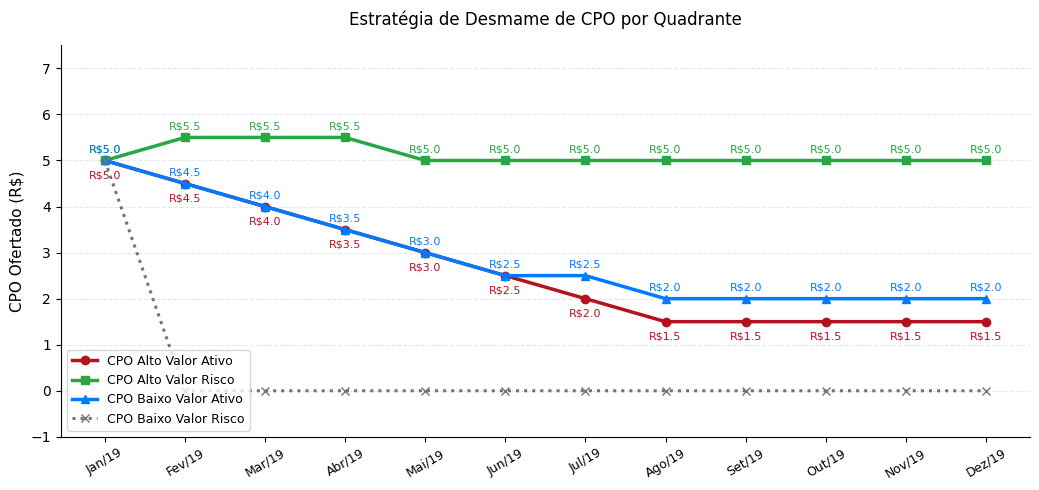

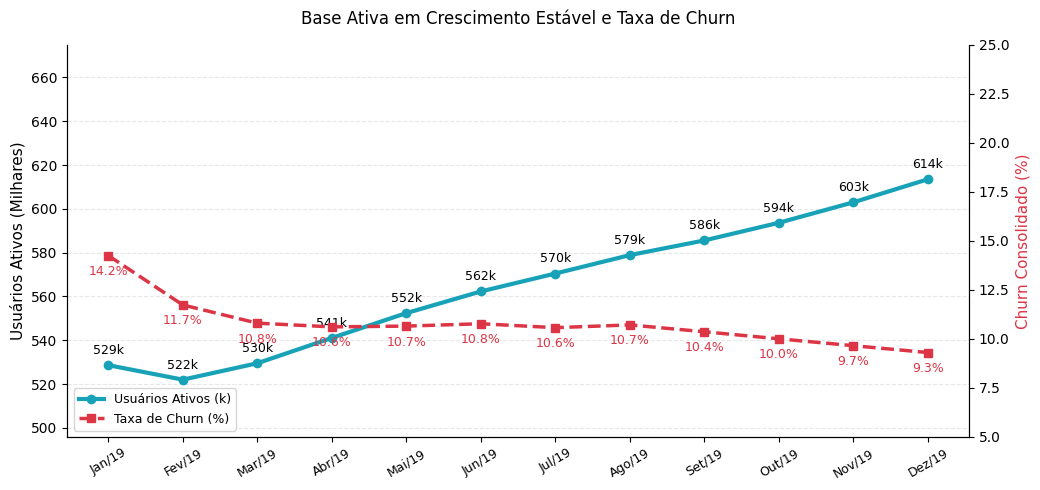

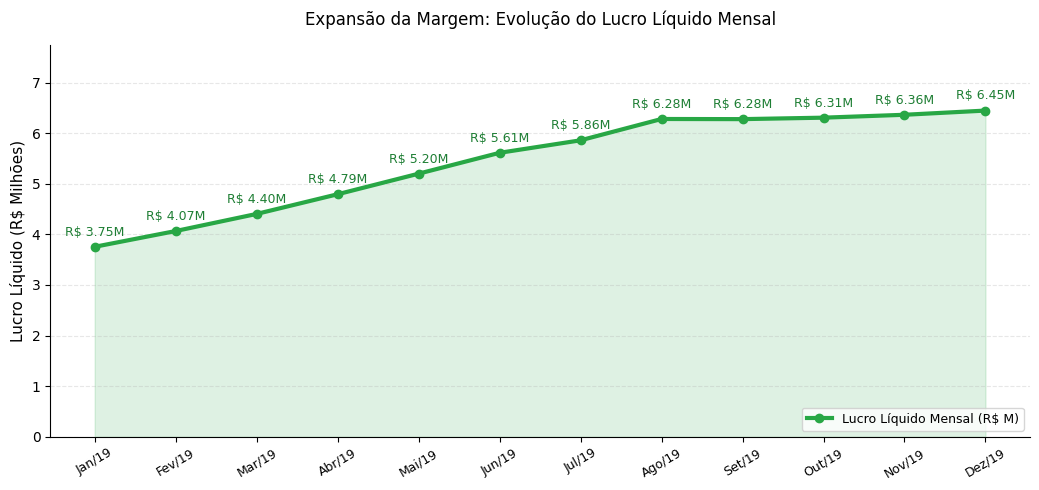

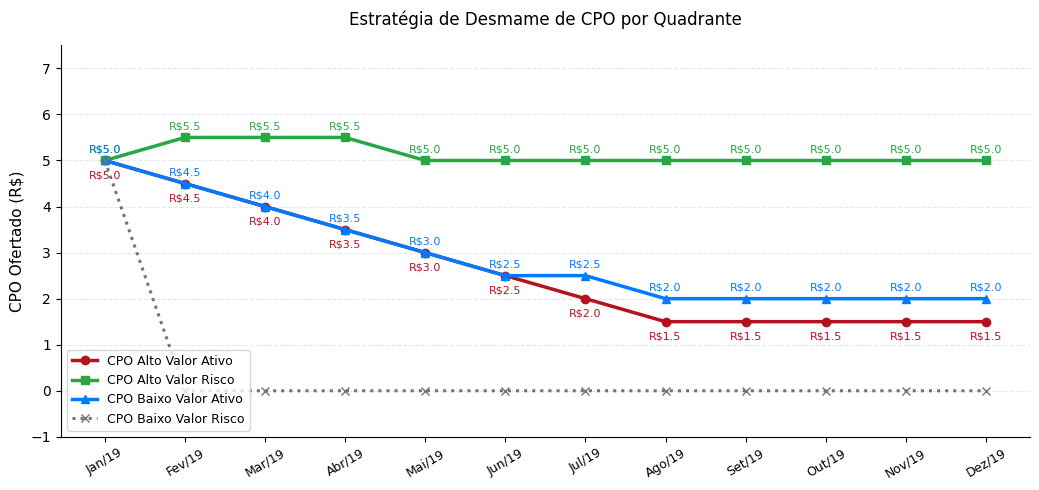

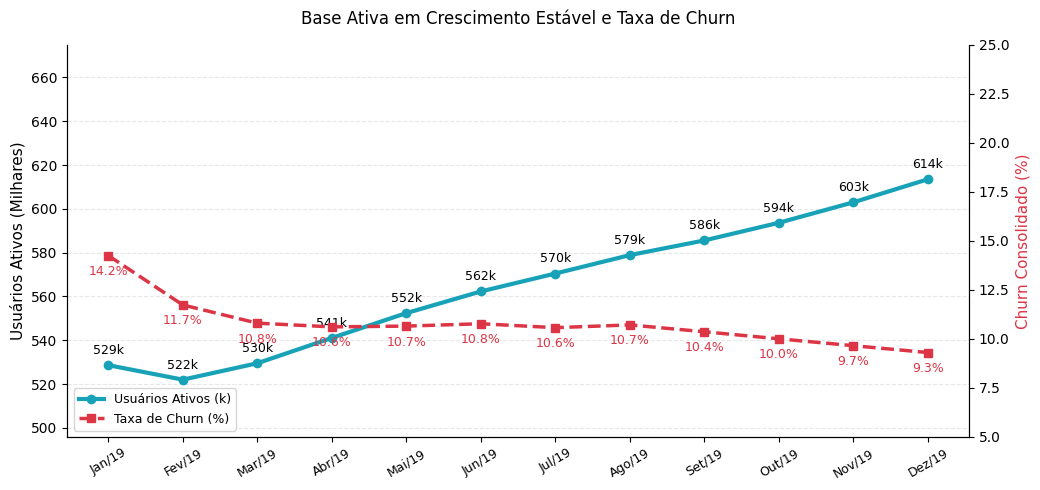

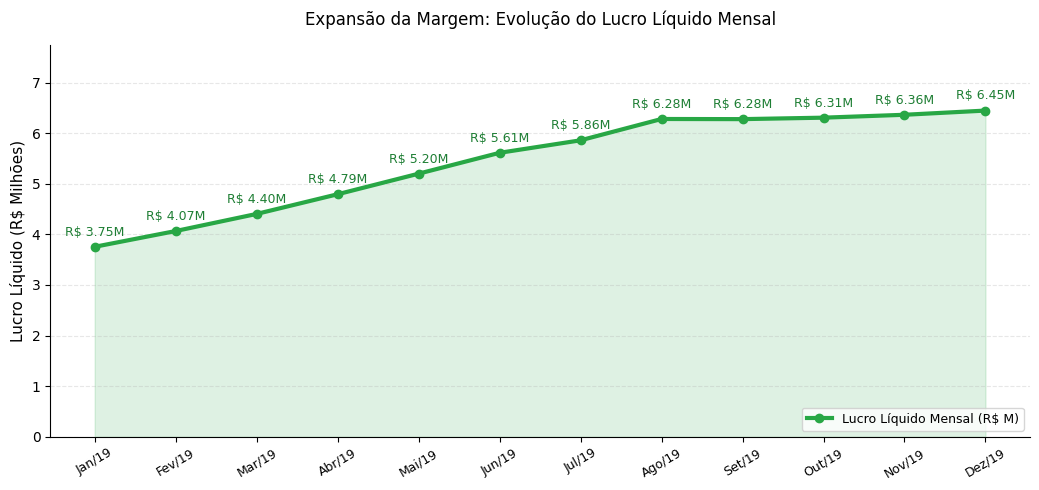

In [0]:
plt.close('all')

# ==============================================================================
# 1. MAPEAMENTO DOS 4 QUADRANTES E CONCILIAÇÃO DA BASE ATIVA (JAN/19)
# ==============================================================================
df_quadrantes = (
    df_segmentos_rfv
    .withColumn("quadrante",
        F.when(F.col("segmento_rfv").isin("Campeões", "Clientes Fiéis"), "AVA")
        .when(F.col("segmento_rfv").isin("Não Podemos Perder", "Em Risco"), "AVR")
        .when(F.col("segmento_rfv").isin("Novos Clientes", "Potenciais Fiéis", "Promissores", "Precisam de Atenção"), "BVA")
        .otherwise("BVR")
    )
)

# Base ativa inicial de compradores em Jan/19 por quadrante
df_compradores_jan19 = (
    orders
    .filter(F.col("reference_month") == "2019-01-01")
    .select("customer_id")
    .distinct()
    .join(df_quadrantes.select("customer_id", "quadrante"), on="customer_id", how="inner")
    .groupBy("quadrante")
    .agg(F.countDistinct("customer_id").alias("count"))
    .toPandas()
    .set_index("quadrante")
)

quadrantes = ["AVA", "AVR", "BVA", "BVR"]
pop_inicial = np.array([float(df_compradores_jan19.loc[q, "count"]) if q in df_compradores_jan19.index else 0.0 for q in quadrantes])
total_ativos_jan_real = int(pop_inicial.sum())

print(f"Total Base Ativa Inicial Conciliada (Jan/19): {total_ativos_jan_real:,} usuários.")
for q in quadrantes:
    print(f"  - {q}: {int(df_compradores_jan19.loc[q, 'count']):,} usuários")

# Métricas reais de Ticket Médio (AOV) e Frequência observadas em Jan/19
df_jan19_metricas = (
    orders
    .filter(F.col("reference_month") == "2019-01-01")
    .join(df_quadrantes.select("customer_id", "quadrante"), on="customer_id", how="inner")
    .groupBy("quadrante")
    .agg(
        F.countDistinct("customer_id").alias("active_users"),
        F.count("order_id").alias("total_orders"),
        F.sum("order_total_amount").alias("total_gmv")
    )
    .withColumn("freq", F.col("total_orders") / F.col("active_users"))
    .withColumn("aov", F.col("total_gmv") / F.col("total_orders"))
    .toPandas()
    .set_index("quadrante")
)

premissas_metricas = {}
for q in quadrantes:
    aov_real = float(df_jan19_metricas.loc[q, "aov"]) if q in df_jan19_metricas.index else 45.0
    freq_real = float(df_jan19_metricas.loc[q, "freq"]) if q in df_jan19_metricas.index else 1.10
    premissas_metricas[q] = {"aov": aov_real, "freq": freq_real}

take_rate = 0.15
adocao_cupom = 0.75

# 1. Aquisição = 13% sobre a base ativa M0 e custo de onboarding R$ 5,50
AQUISICAO_MENSAL = float(round(total_ativos_jan_real * 0.13))
CUSTO_ONBOARDING = 5.5

# Taxas Churn Iniciais
# - Grupos Ativos (AVA, BVA): 15% de churn orgânico base
# - Grupos em Risco (AVR, BVR): 70% de churn orgânico base
CHURN_BASE = {
    "AVA": 0.15,
    "AVR": 0.70,
    "BVA": 0.15,
    "BVR": 0.70
}

# Sensibilidade linear ao CPO
sensibilidade_cpo = 0.010

# Ganho de recorrência mensal (hábito)
reducao_churn_habito = 0.0035

print("\n--- REGRAS DE CHURN LINEAR SIMPLIFICADAS ---")
for q in quadrantes:
    tipo = "Ativo" if CHURN_BASE[q] == 0.15 else "Em Risco"
    print(f"{q} ({tipo}) -> Churn Base: {CHURN_BASE[q]*100:.0f}% | Sensibilidade CPO: -{sensibilidade_cpo*100:.1f} pp/R$")

# CPOs planejados 12M
cpo_politica = {
    "AVA": [5.0, 4.5, 4.0, 3.5, 3.0, 2.5, 2.0, 1.5, 1.5, 1.5, 1.5, 1.5],
    "AVR": [5.0, 5.5, 5.5, 5.5, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0],
    "BVA": [5.0, 4.5, 4.0, 3.5, 3.0, 2.5, 2.5, 2.0, 2.0, 2.0, 2.0, 2.0],
    "BVR": [5.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
}

rotulos_meses = ["Jan/19", "Fev/19", "Mar/19", "Abr/19", "Mai/19", "Jun/19", "Jul/19", "Ago/19", "Set/19", "Out/19", "Nov/19", "Dez/19"]

# Simulação Mês a Mês
meses = 12
u_ava, u_avr, u_bva, u_bvr = pop_inicial
dados_simulacao = []

for m in range(meses):
    mes_str = rotulos_meses[m]
    total_ativos_inicio = u_ava + u_avr + u_bva + u_bvr
    
    # CPOs aplicados no mês
    c_ava = cpo_politica["AVA"][m]
    c_avr = cpo_politica["AVR"][m]
    c_bva = cpo_politica["BVA"][m]
    c_bvr = cpo_politica["BVR"][m]
    
    # Volume de pedidos
    p_ava = u_ava * premissas_metricas["AVA"]["freq"]
    p_avr = u_avr * premissas_metricas["AVR"]["freq"]
    p_bva = u_bva * premissas_metricas["BVA"]["freq"]
    p_bvr = u_bvr * premissas_metricas["BVR"]["freq"]
    
    total_pedidos_ativos = p_ava + p_avr + p_bva + p_bvr
    frequencia_geral = total_pedidos_ativos / total_ativos_inicio if total_ativos_inicio > 0 else 0.0
    
    # Custos de Marketing (Cupons com taxa de adoção + Onboarding fixo)
    cost_cupons_ava = p_ava * c_ava * adocao_cupom
    cost_cupons_avr = p_avr * c_avr * adocao_cupom
    cost_cupons_bva = p_bva * c_bva * adocao_cupom
    cost_cupons_bvr = p_bvr * c_bvr * (adocao_cupom if c_bvr > 0 else 0.0)
    cost_marketing_total = cost_cupons_ava + cost_cupons_avr + cost_cupons_bva + cost_cupons_bvr + (AQUISICAO_MENSAL * CUSTO_ONBOARDING)
    
    # Receita Take Rate (15% sobre o GMV)
    rec_ava = p_ava * premissas_metricas["AVA"]["aov"] * take_rate
    rec_avr = p_avr * premissas_metricas["AVR"]["aov"] * take_rate
    rec_bva = p_bva * premissas_metricas["BVA"]["aov"] * take_rate
    rec_bvr = p_bvr * premissas_metricas["BVR"]["aov"] * take_rate
    rec_total_pedidos = rec_ava + rec_avr + rec_bva + rec_bvr
    lucro_pedidos = rec_total_pedidos - cost_marketing_total
    
 
    # Churn = Churn Base - (Sensibilidade * CPO) - Hábito
    churn_ava = max(0.04, CHURN_BASE["AVA"] - (sensibilidade_cpo * c_ava) - (reducao_churn_habito * m))
    churn_avr = max(0.20, CHURN_BASE["AVR"] - (sensibilidade_cpo * c_avr) - (reducao_churn_habito * m))
    churn_bva = max(0.06, CHURN_BASE["BVA"] - (sensibilidade_cpo * c_bva) - (reducao_churn_habito * m))
    churn_bvr = max(0.30, CHURN_BASE["BVR"] - (sensibilidade_cpo * c_bvr) - (reducao_churn_habito * m))
    
    # Churn Total Absoluto e Taxa Consolidada
    churn_usuarios_total = (u_ava * churn_ava) + (u_avr * churn_avr) + (u_bva * churn_bva) + (u_bvr * churn_bvr)
    taxa_churn_total_pct = (churn_usuarios_total / total_ativos_inicio) * 100.0
    
    # Retenção incremental resgatada em AVR comparada ao churn sem cupom (70%)
    usuarios_salvos_avr = max(0.0, (CHURN_BASE["AVR"] - churn_avr) * u_avr)
    lucro_retencao = usuarios_salvos_avr * (premissas_metricas["AVA"]["freq"] * premissas_metricas["AVA"]["aov"] * take_rate)
    lucro_total = lucro_pedidos + lucro_retencao
    
    dados_simulacao.append({
        "mes_referencia": mes_str,
        "cpo_alto_ativo": round(c_ava, 2),
        "cpo_alto_risco": round(c_avr, 2),
        "cpo_baixo_ativo": round(c_bva, 2),
        "cpo_baixo_risco": round(c_bvr, 2),
        "users_alto_ativo": int(round(u_ava)),
        "users_alto_risco": int(round(u_avr)),
        "users_baixo_ativo": int(round(u_bva)),
        "users_baixo_risco": int(round(u_bvr)),
        "total_ativos": int(round(total_ativos_inicio)),
        "freq_geral_pedidos": round(frequencia_geral, 2),
        "aquisicao_mes": int(AQUISICAO_MENSAL),
        "churn_total_usuarios": int(round(churn_usuarios_total)),
        "taxa_churn_total_pct": round(taxa_churn_total_pct, 2),
        "custo_total_marketing": int(round(cost_marketing_total)),
        "lucro_total_liquido": int(round(lucro_total))
    })
    
    # ==============================================================================
    # TRANSIÇÃO CONTÁBIL DIRETA PARA O PRÓXIMO MÊS (SEM MATRIZ):
    # ==============================================================================
    # 1. Usuários sobreviventes de cada grupo
    retidos_ava = u_ava * (1.0 - churn_ava)
    retidos_avr = u_avr * (1.0 - churn_avr)
    retidos_bva = u_bva * (1.0 - churn_bva)
    retidos_bvr = u_bvr * (1.0 - churn_bvr)
    
    # 2. Migração orgânica simples: clientes de baixo valor que sobem de nível (5% do BVA retido vira AVA)
    upgrade_bva_para_ava = retidos_bva * 0.05
    
    # 3. Atualização direta dos saldos de cada grupo para o mês seguinte:
    u_ava = retidos_ava + upgrade_bva_para_ava
    u_avr = retidos_avr
    u_bva = (retidos_bva - upgrade_bva_para_ava) + AQUISICAO_MENSAL  # Entram os novos clientes
    u_bvr = retidos_bvr

df_simulacao_pd = pd.DataFrame(dados_simulacao)

# Gráficos
plt.close('all')

x = np.arange(len(df_simulacao_pd["mes_referencia"]))
meses_labels = df_simulacao_pd["mes_referencia"]

spark.createDataFrame(df_simulacao_pd).display()


# ==============================================================================
# Gráfico 1: Evolução dos CPOs
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(10.5, 5))
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

ax1.plot(x, df_simulacao_pd["cpo_alto_ativo"], marker='o', linewidth=2.5, color='#b5121e', label='CPO Alto Valor Ativo')
ax1.plot(x, df_simulacao_pd["cpo_alto_risco"], marker='s', linewidth=2.5, color='#28a745', label='CPO Alto Valor Risco')
ax1.plot(x, df_simulacao_pd["cpo_baixo_ativo"], marker='^', linewidth=2.5, color='#007bff', label='CPO Baixo Valor Ativo')
ax1.plot(x, df_simulacao_pd["cpo_baixo_risco"], marker='x', linewidth=2.2, color='#6c757d', linestyle=':', label='CPO Baixo Valor Risco')

for i in range(len(x)):
    ax1.annotate(f"R${df_simulacao_pd['cpo_alto_ativo'][i]:.1f}", (x[i], df_simulacao_pd['cpo_alto_ativo'][i]), 
                 textcoords="offset points", xytext=(0, -13), ha='center', fontsize=8, color='#b5121e')
    ax1.annotate(f"R${df_simulacao_pd['cpo_alto_risco'][i]:.1f}", (x[i], df_simulacao_pd['cpo_alto_risco'][i]), 
                 textcoords="offset points", xytext=(0, 6), ha='center', fontsize=8, color='#28a745')
    ax1.annotate(f"R${df_simulacao_pd['cpo_baixo_ativo'][i]:.1f}", (x[i], df_simulacao_pd['cpo_baixo_ativo'][i]), 
                 textcoords="offset points", xytext=(0, 6), ha='center', fontsize=8, color='#007bff')

ax1.set_title("Estratégia de Desmame de CPO por Quadrante", fontsize=12, pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(meses_labels, fontsize=9, rotation=30)
ax1.set_ylabel("CPO Ofertado (R$)", fontsize=11)
ax1.set_ylim(-1.0, 7.5)
ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1.legend(loc='lower left', frameon=True, facecolor='white', fontsize=9)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
plt.tight_layout()
display(fig1)

# ==============================================================================
# Gráfico 2: Base Ativa e Taxa de Churn
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(10.5, 5))
ax2.plot(x, df_simulacao_pd["total_ativos"] / 1e3, marker='o', linewidth=3, color='#17a2b8', label='Usuários Ativos (k)')
for i, txt in enumerate(df_simulacao_pd["total_ativos"]):
    ax2.annotate(f"{txt/1e3:.0f}k", (x[i], txt/1e3), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)

ax2.set_title("Base Ativa em Crescimento Estável e Taxa de Churn", fontsize=12, pad=15)
ax2.set_xticks(x)
ax2.set_xticklabels(meses_labels, fontsize=9, rotation=30)
ax2.set_ylabel("Usuários Ativos (Milhares)", fontsize=11)
ax2.set_ylim(min(df_simulacao_pd["total_ativos"] / 1e3) * 0.95, max(df_simulacao_pd["total_ativos"] / 1e3) * 1.10)
ax2.grid(axis='y', linestyle='--', alpha=0.3)

ax2_twin = ax2.twinx()
ax2_twin.plot(x, df_simulacao_pd["taxa_churn_total_pct"], color='#dc3545', linestyle='--', linewidth=2.5, marker='s', label='Taxa de Churn (%)')
for i, churn in enumerate(df_simulacao_pd["taxa_churn_total_pct"]):
    ax2_twin.annotate(f"{churn:.1f}%", (x[i], churn), textcoords="offset points", xytext=(0, -14), ha='center', fontsize=9, color='#dc3545')

ax2_twin.set_ylabel("Churn Consolidado (%)", fontsize=11, color='#dc3545')
ax2_twin.set_ylim(5.0, 25.0)
ax2_twin.spines['top'].set_visible(False)

lines_1, labels_1 = ax2.get_legend_handles_labels()
lines_2, labels_2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower left', frameon=True, facecolor='white', fontsize=9)
ax2.spines['top'].set_visible(False)
plt.tight_layout()
display(fig2)

# ==============================================================================
# Gráfico 3: Evolução do Lucro Líquido Mensal
# ==============================================================================
fig3, ax3 = plt.subplots(figsize=(10.5, 5))
lucro_milhoes = df_simulacao_pd["lucro_total_liquido"] / 1e6

ax3.plot(x, lucro_milhoes, marker='o', linewidth=3, color='#28a745', label='Lucro Líquido Mensal (R$ M)')
ax3.fill_between(x, lucro_milhoes, 0, alpha=0.15, color='#28a745')

for i, val in enumerate(lucro_milhoes):
    ax3.annotate(f"R$ {val:.2f}M", (x[i], val), 
                 textcoords="offset points", xytext=(0, 8), ha='center', 
                 fontsize=9, color='#1e7e34')

ax3.set_title("Expansão da Margem: Evolução do Lucro Líquido Mensal", fontsize=12, pad=15)
ax3.set_xticks(x)
ax3.set_xticklabels(meses_labels, fontsize=9, rotation=30)
ax3.set_ylabel("Lucro Líquido (R$ Milhões)", fontsize=11)
ax3.set_ylim(0, max(lucro_milhoes) * 1.20)
ax3.grid(axis='y', linestyle='--', alpha=0.3)
ax3.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
plt.tight_layout()
display(fig3)

In [0]:
end_time_notebook = time.time()
total_duration_seconds = end_time_notebook - start_time_notebook
total_duration_minutes = total_duration_seconds / 60
analytics_duration_seconds = total_duration_seconds - etl_duration_seconds
analytics_duration_minutes = total_duration_minutes - etl_duration_minutes

print("="*60)
print("🚀 EXECUÇÃO DO NOTEBOOK CONCLUÍDA")
print("="*60)
print(f"⏱️ Tempo ETL: {etl_duration_minutes:.2f} min")
print(f"⏱️ Tempo Análise: {analytics_duration_minutes:.2f} min")
print("-" * 60)
print(f"🕒 TEMPO TOTAL DE EXECUÇÃO: {total_duration_seconds:.2f} segundos ({total_duration_minutes:.2f} minutos)")
print("="*60)

🚀 EXECUÇÃO DO NOTEBOOK CONCLUÍDA
⏱️ Tempo ETL: 4.53 min
⏱️ Tempo Análise: 3.16 min
------------------------------------------------------------
🕒 TEMPO TOTAL DE EXECUÇÃO: 461.68 segundos (7.69 minutos)
